# M51 — Final Evaluation

## AuthentiScore

This notebook performs the final evaluation of the AuthentiScore Random Forest classifier on a held-out test dataset.

### Model
- Random Forest Classifier
- n_estimators = 300
- random_state = 42
- n_jobs = -1

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

Additional outputs:
- Classification report
- Confusion matrix
- Confusion matrix visualization

In [1]:
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

In [2]:
CURRENT_DIR = Path.cwd()

print("Current directory:")
print(CURRENT_DIR)

possible_roots = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
    CURRENT_DIR.parent.parent
]

PROJECT_ROOT = None

for root in possible_roots:
    if (
        (root / "data").exists()
        and (root / "backend").exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate AuthentiScore project root."
    )

print("\nProject root:")
print(PROJECT_ROOT)

Current directory:
c:\Users\Acer\Documents\AuthentiScore\notebooks

Project root:
c:\Users\Acer\Documents\AuthentiScore


In [3]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "backend" / "trained_models"

DATASET_PATH = PROCESSED_DIR / "instagram_features.csv"
MODEL_PATH = MODEL_DIR / "authentiscore_rf_v1.pkl"

print("Dataset:")
print(DATASET_PATH)

print("\nProduction model:")
print(MODEL_PATH)

Dataset:
c:\Users\Acer\Documents\AuthentiScore\data\processed\instagram_features.csv

Production model:
c:\Users\Acer\Documents\AuthentiScore\backend\trained_models\authentiscore_rf_v1.pkl


In [4]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATASET_PATH}"
    )

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Production model not found:\n{MODEL_PATH}"
    )

print("✓ Dataset found")
print("✓ Production model found")

✓ Dataset found
✓ Production model found


In [5]:
df = pd.read_csv(DATASET_PATH)

print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset shape:
(696, 10)

Columns:
['followers', 'following', 'posts', 'bio_length', 'has_profile_picture', 'is_private', 'username_digit_ratio', 'fake', 'follower_following_ratio', 'profile_completeness']


In [6]:
possible_label_columns = [
    "label",
    "is_fake",
    "fake",
    "target",
    "class"
]

label_column = None

for column in possible_label_columns:
    if column in df.columns:
        label_column = column
        break

if label_column is None:
    raise ValueError(
        "Could not find target column."
    )

print("Label column:")
print(label_column)

print("\nLabel distribution:")
print(df[label_column].value_counts())

Label column:
fake

Label distribution:
fake
0    348
1    348
Name: count, dtype: int64


In [7]:
FEATURE_COLUMNS = [
    "followers",
    "following",
    "posts",
    "bio_length",
    "has_profile_picture",
    "is_private",
    "username_digit_ratio",
    "follower_following_ratio",
    "profile_completeness"
]

missing_features = [
    feature
    for feature in FEATURE_COLUMNS
    if feature not in df.columns
]

if missing_features:
    raise ValueError(
        "Missing features:\n"
        + "\n".join(missing_features)
    )

print("✓ All 9 features available")

✓ All 9 features available


In [8]:
X = df[FEATURE_COLUMNS].copy()
y = df[label_column].copy()

for column in FEATURE_COLUMNS:
    X[column] = pd.to_numeric(
        X[column],
        errors="coerce"
    )

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (696, 9)
y shape: (696,)


In [9]:
unique_labels = sorted(
    y.dropna().unique().tolist(),
    key=lambda value: str(value)
)

print("Original labels:")
print(unique_labels)

if set(unique_labels).issubset({0, 1}):
    y_binary = y.astype(int)

elif set(unique_labels).issubset({False, True}):
    y_binary = y.astype(int)

else:
    if len(unique_labels) != 2:
        raise ValueError(
            f"Expected binary labels, found: {unique_labels}"
        )

    label_mapping = {
        unique_labels[0]: 0,
        unique_labels[1]: 1
    }

    y_binary = y.map(
        label_mapping
    ).astype(int)

    print("\nLabel mapping:")
    print(label_mapping)

print("\nFinal labels:")
print(y_binary.value_counts())

Original labels:
[0, 1]

Final labels:
fake
0    348
1    348
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 556
Testing samples : 140

Training distribution:
fake
0    278
1    278
Name: count, dtype: int64

Testing distribution:
fake
1    70
0    70
Name: count, dtype: int64


In [11]:
production_model = joblib.load(
    MODEL_PATH
)

print("✓ Production model loaded")
print("Model type:", type(production_model))

✓ Production model loaded
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [12]:
if hasattr(
    production_model,
    "n_features_in_"
):
    print(
        "Model expects:",
        production_model.n_features_in_,
        "features"
    )

    print(
        "Dataset provides:",
        X_test.shape[1],
        "features"
    )

    if (
        production_model.n_features_in_
        != X_test.shape[1]
    ):
        raise ValueError(
            "Model feature count does not match dataset."
        )

print("✓ Feature count verified")

Model expects: 9 features
Dataset provides: 9 features
✓ Feature count verified


In [13]:
predictions = production_model.predict(
    X_test
)

probabilities = production_model.predict_proba(
    X_test
)[:, 1]

print("✓ Predictions generated")

print("\nFirst 10 predictions:")
print(predictions[:10])

print("\nFirst 10 probabilities:")
print(probabilities[:10])

✓ Predictions generated

First 10 predictions:
[0 0 1 0 0 1 0 1 1 0]

First 10 probabilities:
[0.28666667 0.         1.         0.06666667 0.00666667 0.61333333
 0.         0.88       0.83333333 0.31333333]


In [14]:
accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    probabilities
)

print("=" * 60)
print("M51 — FINAL EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {roc_auc * 100:.2f}%")

M51 — FINAL EVALUATION
Accuracy  : 89.29%
Precision : 91.04%
Recall    : 87.14%
F1 Score  : 89.05%
ROC-AUC   : 96.42%


In [15]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=[
            "Genuine",
            "Fake/Spam"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Genuine       0.88      0.91      0.90        70
   Fake/Spam       0.91      0.87      0.89        70

    accuracy                           0.89       140
   macro avg       0.89      0.89      0.89       140
weighted avg       0.89      0.89      0.89       140



In [16]:
cm = confusion_matrix(
    y_test,
    predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[64  6]
 [ 9 61]]


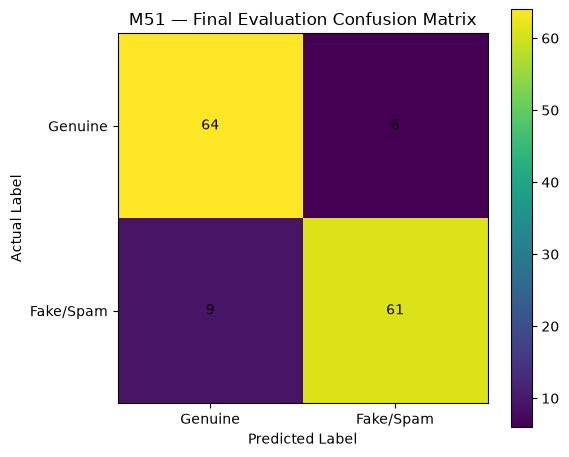

In [17]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title(
    "M51 — Final Evaluation Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Genuine", "Fake/Spam"]
)

plt.yticks(
    [0, 1],
    ["Genuine", "Fake/Spam"]
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()
plt.show()

In [18]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    "Percentage": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100,
        roc_auc * 100
    ]
})

final_metrics["Percentage"] = (
    final_metrics["Percentage"].round(2)
)

display(final_metrics)

,Metric,Score,Percentage
0,Accuracy,0.892857,89.29
1,Precision,0.910448,91.04
2,Recall,0.871429,87.14
3,F1,0.890511,89.05
4,ROC-AUC,0.964184,96.42


In [19]:
FINAL_METRICS_PATH = (
    PROCESSED_DIR /
    "final_evaluation_metrics.csv"
)

final_metrics.to_csv(
    FINAL_METRICS_PATH,
    index=False
)

print("✓ Final metrics saved:")
print(FINAL_METRICS_PATH)

✓ Final metrics saved:
c:\Users\Acer\Documents\AuthentiScore\data\processed\final_evaluation_metrics.csv


In [20]:
FINAL_CM_PATH = (
    PROCESSED_DIR /
    "final_confusion_matrix.csv"
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual_Genuine",
        "Actual_Fake"
    ],
    columns=[
        "Predicted_Genuine",
        "Predicted_Fake"
    ]
)

cm_df.to_csv(
    FINAL_CM_PATH
)

print("✓ Confusion matrix saved:")
print(FINAL_CM_PATH)

✓ Confusion matrix saved:
c:\Users\Acer\Documents\AuthentiScore\data\processed\final_confusion_matrix.csv


In [21]:
print("=" * 60)
print("M51 — FINAL EVALUATION COMPLETE")
print("=" * 60)

print("\nTest samples:", len(y_test))

print("\nFinal Performance:")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {roc_auc * 100:.2f}%")

print("\nOutput files:")
print(f"1. {FINAL_METRICS_PATH}")
print(f"2. {FINAL_CM_PATH}")

print("\nM51 completed.")

M51 — FINAL EVALUATION COMPLETE

Test samples: 140

Final Performance:
Accuracy  : 89.29%
Precision : 91.04%
Recall    : 87.14%
F1 Score  : 89.05%
ROC-AUC   : 96.42%

Output files:
1. c:\Users\Acer\Documents\AuthentiScore\data\processed\final_evaluation_metrics.csv
2. c:\Users\Acer\Documents\AuthentiScore\data\processed\final_confusion_matrix.csv

M51 completed.
